# Lab 7-01：為什麼需要 MCP——拆開來看，它只是一行一行的 JSON

**目標**：先親手體會「同一個工具要為每個 app 各寫一次轉接」有多煩，再用 40 行 Python
手寫一個迷你 server，用 subprocess 跟它講話，看清楚 MCP 底層就是 stdin/stdout 上的 JSON 訊息。

**你會學到**
- 各家模型 API 的工具格式長得不一樣，N 個 app × M 個工具會變成 N×M 份轉接程式
- MCP 的三個角色：Host、Client、Server，各自負責什麼
- JSON-RPC 的請求、回應、通知長什麼樣，`id` 用來做什麼
- 為什麼 stdio server 裡不能隨手 `print()`

**前置**：會寫 Python 函式、知道 subprocess 是什麼。這本不需要模型；最後一步會啟動 `servers/ops_server.py`。

**對應投影片**：「MCP 是什麼」「N×M 整合爆炸」「三角色架構」「傳輸：stdio 與 HTTP」「踩坑：連不上」

```
                        N×M 變成 N+M

    沒有標準：9 份轉接                      有 MCP：3 + 3 份
 ┌──────────┐   ┌──────────┐      ┌──────────┐       ┌──────────┐
 │  Claude  │─┬─│ 日誌工具 │      │  Claude  │──▶┃ ┃──▶│ 日誌工具 │
 └──────────┘ ╳ └──────────┘      └──────────┘  ┃M┃  └──────────┘
 ┌──────────┐ ╳ ┌──────────┐      ┌──────────┐  ┃C┃  ┌──────────┐
 │  Cursor  │─┼─│Excel 工具│      │  Cursor  │──▶┃P┃──▶│Excel 工具│
 └──────────┘ ╳ └──────────┘      └──────────┘  ┃ ┃  └──────────┘
 ┌──────────┐ ╳ ┌──────────┐      ┌──────────┐  ┃ ┃  ┌──────────┐
 │客服機器人│─┴─│資料庫工具│      │客服機器人│──▶┃ ┃──▶│資料庫工具│
 └──────────┘   └──────────┘      └──────────┘       └──────────┘
  每個 app 跟每個工具都連一條        每個 app、每個工具只接一次
```

*圖：左邊沒有標準，每個 app 跟每個工具各要一份轉接（交錯的線）；右邊有了 MCP，每個 app 和每個工具都只接到中間那條協定上一次。*

In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

## Step 1：一個工具，三種寫法

假設你寫了一個查服務狀態的函式，想讓模型能呼叫它。模組 5 學過：要把函式的名稱、說明、參數格式交給模型。
問題是每家 API 要的格式都不一樣。下面是同一個工具，分別寫成 OpenAI、Anthropic、Gemini 要的樣子。

In [2]:
def get_service_status(service: str) -> str:
    """查詢一個服務目前的狀態。"""
    return f"{service}: healthy"


params = {"type": "object", "properties": {"service": {"type": "string"}}, "required": ["service"]}
desc = "查詢一個服務目前的狀態。"

openai_style = {"type": "function", "function": {"name": "get_service_status", "description": desc, "parameters": params}}
anthropic_style = {"name": "get_service_status", "description": desc, "input_schema": params}
gemini_style = {"function_declarations": [{"name": "get_service_status", "description": desc, "parameters": params}]}

for name, spec in [("OpenAI", openai_style), ("Anthropic", anthropic_style), ("Gemini", gemini_style)]:
    print(f"--- {name}\n{json.dumps(spec, ensure_ascii=False)}")

--- OpenAI
{"type": "function", "function": {"name": "get_service_status", "description": "查詢一個服務目前的狀態。", "parameters": {"type": "object", "properties": {"service": {"type": "string"}}, "required": ["service"]}}}
--- Anthropic
{"name": "get_service_status", "description": "查詢一個服務目前的狀態。", "input_schema": {"type": "object", "properties": {"service": {"type": "string"}}, "required": ["service"]}}
--- Gemini
{"function_declarations": [{"name": "get_service_status", "description": "查詢一個服務目前的狀態。", "parameters": {"type": "object", "properties": {"service": {"type": "string"}}, "required": ["service"]}}]}


核心資訊（名稱、說明、JSON Schema）完全一樣，只是外面包的那層不同：`function.parameters`、`input_schema`、`function_declarations`。
模型回傳「我要呼叫工具」的格式也各不相同，所以解析那一段也要各寫一份。

這還只是模型 API。真正的痛在 app 端：Claude Desktop、Cursor、你們公司的客服機器人，各有各的外掛機制。

## Step 2：算一算要寫幾份轉接

沒有標準時，每個 app 都要為每個工具寫一份轉接：N 個 app、M 個工具，就是 N×M 份。
有了共同協定，工具端每個寫一次 server（M 份），app 端每個寫一次 client（N 份），總共 N+M。

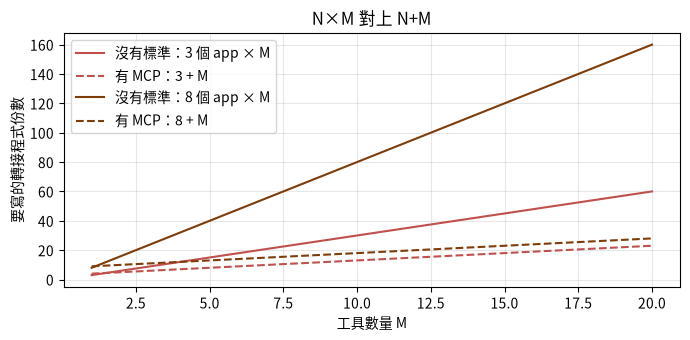

8 個 app、20 個工具： 160 份 對上 28 份


In [3]:
tools = range(1, 21)
fig, ax = plt.subplots(figsize=(7, 3.5))
for n_apps, color in [(3, "#c0504d"), (8, "#7f3b08")]:
    ax.plot(tools, [n_apps * m for m in tools], color=color, label=f"沒有標準：{n_apps} 個 app × M")
    ax.plot(tools, [n_apps + m for m in tools], color=color, linestyle="--", label=f"有 MCP：{n_apps} + M")
ax.set_xlabel("工具數量 M")
ax.set_ylabel("要寫的轉接程式份數")
ax.set_title("N×M 對上 N+M")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("8 個 app、20 個工具：", 8 * 20, "份 對上", 8 + 20, "份")

這跟 USB 出現之前的情況一樣：每台印表機配一條專用線。MCP（Model Context Protocol）就是在定這個插頭的形狀。

## Step 3：三個角色

```
┌──────────────── Host（使用者在用的 app）────────────────┐
│  Claude Desktop / Cursor / 你的 notebook                │
│                                                          │
│   模型  ←→  Client A ──────────┐                        │
│             Client B ───────┐  │                        │
└─────────────────────────────┼──┼────────────────────────┘
                              │  │  每個 Client 只連一個 Server
                    ┌─────────▼┐ ┌▼─────────┐
                    │ Server B │ │ Server A │  提供 tools / resources / prompts
                    │ Excel    │ │ 維運日誌 │
                    └──────────┘ └──────────┘
```

- **Host**：使用者打開的那個應用程式，裡面有模型，負責決定要不要真的執行工具。
- **Client**：Host 裡負責「跟一個 server 講話」的連線物件，一對一。
- **Server**：把能力包起來的小程式。它不知道對面是哪家模型，只回答「我有什麼」「幫你做這件事」。

模型本身不直接碰 server；模型說「我想呼叫某工具」，Host 透過 Client 去叫。

## Step 4：訊息格式——JSON-RPC 2.0

MCP 的每一則訊息都是 JSON-RPC 2.0。只有三種：
- **請求**：有 `id`、`method`、`params`，對方一定要回。
- **回應**：帶著同一個 `id`，裡面是 `result` 或 `error`。
- **通知**：沒有 `id`，對方不用回。

In [4]:
request = {"jsonrpc": "2.0", "id": 1, "method": "tools/call",
           "params": {"name": "add", "arguments": {"a": 2, "b": 3}}}
response = {"jsonrpc": "2.0", "id": 1, "result": {"content": [{"type": "text", "text": "5"}]}}
notification = {"jsonrpc": "2.0", "method": "notifications/initialized"}

for label, msg in [("請求", request), ("回應", response), ("通知", notification)]:
    print(f"{label}：{json.dumps(msg, ensure_ascii=False)}")

請求：{"jsonrpc": "2.0", "id": 1, "method": "tools/call", "params": {"name": "add", "arguments": {"a": 2, "b": 3}}}
回應：{"jsonrpc": "2.0", "id": 1, "result": {"content": [{"type": "text", "text": "5"}]}}
通知：{"jsonrpc": "2.0", "method": "notifications/initialized"}


`id` 的用途：client 可以連續送好幾個請求，回應回來的順序不一定一樣，靠 `id` 對回去是哪一題的答案。

## Step 5：手寫一個迷你 server

stdio 傳輸的規則很簡單：**server 從 stdin 讀一行 JSON，往 stdout 寫一行 JSON**。
下面這個 server 會回答三種請求：`initialize`（打招呼）、`tools/list`（我有哪些工具）、`tools/call`（幫我執行）。

In [5]:
%%writefile outputs/mini_server.py
import json
import sys

TOOLS = {
    "add": (lambda a, b: a + b, {"a": "number", "b": "number"}, "兩數相加"),
    "count_chars": (lambda text: len(text), {"text": "string"}, "計算字數"),
}


def handle(method, params):
    if method == "initialize":
        return {"serverInfo": {"name": "mini", "version": "0.1"}, "capabilities": {"tools": {}}}
    if method == "tools/list":
        return {"tools": [
            {"name": n, "description": d,
             "inputSchema": {"type": "object", "properties": {k: {"type": t} for k, t in args.items()}}}
            for n, (_, args, d) in TOOLS.items()
        ]}
    if method == "tools/call":
        if params["name"] not in TOOLS:
            raise ValueError(f"沒有這個工具：{params['name']}")
        fn = TOOLS[params["name"]][0]
        return {"content": [{"type": "text", "text": str(fn(**params["arguments"]))}]}
    raise ValueError(f"不認得的 method：{method}")


for line in sys.stdin:                      # 一行一則訊息
    msg = json.loads(line)
    if "id" not in msg:                     # 通知：不用回
        continue
    try:
        reply = {"jsonrpc": "2.0", "id": msg["id"], "result": handle(msg["method"], msg.get("params", {}))}
    except Exception as exc:
        reply = {"jsonrpc": "2.0", "id": msg["id"], "error": {"code": -32603, "message": str(exc)}}
    print(json.dumps(reply, ensure_ascii=False), flush=True)   # stdout 就是協定通道

Writing outputs/mini_server.py


注意最後一行的 `print`：在這裡 stdout **就是**協定通道，印出去的每一行都會被 client 當成 JSON 解析。
這件事等一下會讓我們踩坑。

## Step 6：當 client——用 subprocess 跟它講話

Host 啟動 stdio server 的方式就是開一個子行程，把 stdin/stdout 接上管線。我們自己來做一次，並記下每則訊息的時間，等一下畫時序圖。

In [6]:
log = []  # (方向, 內容摘要, 往返毫秒)


def start(script: str) -> subprocess.Popen:
    return subprocess.Popen([sys.executable, script], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                            stderr=subprocess.PIPE, text=True, encoding="utf-8")


def send(proc: subprocess.Popen, msg: dict) -> dict | None:
    t0 = time.perf_counter()
    proc.stdin.write(json.dumps(msg, ensure_ascii=False) + "\n")
    proc.stdin.flush()
    log.append(("→", f"{msg['method']}" + (f"（id={msg['id']}）" if "id" in msg else "（通知）"), None))
    print("→", json.dumps(msg, ensure_ascii=False))
    if "id" not in msg:                     # 通知不等回應
        return None
    line = proc.stdout.readline()
    ms = (time.perf_counter() - t0) * 1000
    kind = "error" if '"error"' in line else "result"
    log.append(("←", f"{kind}（id={msg['id']}）", ms))
    print("←", line.strip()[:300] + (" …（後面截斷）" if len(line) > 300 else ""))
    return json.loads(line)


mini = start("outputs/mini_server.py")
send(mini, {"jsonrpc": "2.0", "id": 1, "method": "initialize", "params": {}})
send(mini, {"jsonrpc": "2.0", "method": "notifications/initialized"})

→ {"jsonrpc": "2.0", "id": 1, "method": "initialize", "params": {}}
← {"jsonrpc": "2.0", "id": 1, "result": {"serverInfo": {"name": "mini", "version": "0.1"}, "capabilities": {"tools": {}}}}
→ {"jsonrpc": "2.0", "method": "notifications/initialized"}


In [7]:
_ = send(mini, {"jsonrpc": "2.0", "id": 2, "method": "tools/list"})

→ {"jsonrpc": "2.0", "id": 2, "method": "tools/list"}
← {"jsonrpc": "2.0", "id": 2, "result": {"tools": [{"name": "add", "description": "兩數相加", "inputSchema": {"type": "object", "properties": {"a": {"type": "number"}, "b": {"type": "number"}}}}, {"name": "count_chars", "description": "計算字數", "inputSchema": {"type": "object", "properties": {"text": {"type …（後面截斷）


In [8]:
send(mini, {"jsonrpc": "2.0", "id": 3, "method": "tools/call", "params": {"name": "add", "arguments": {"a": 2, "b": 3}}})
send(mini, {"jsonrpc": "2.0", "id": 4, "method": "tools/call",
            "params": {"name": "count_chars", "arguments": {"text": "星港物流付款服務降級"}}})
send(mini, {"jsonrpc": "2.0", "id": 5, "method": "tools/call", "params": {"name": "delete_all", "arguments": {}}})
mini.stdin.close()
_ = mini.wait()

→ {"jsonrpc": "2.0", "id": 3, "method": "tools/call", "params": {"name": "add", "arguments": {"a": 2, "b": 3}}}
← {"jsonrpc": "2.0", "id": 3, "result": {"content": [{"type": "text", "text": "5"}]}}
→ {"jsonrpc": "2.0", "id": 4, "method": "tools/call", "params": {"name": "count_chars", "arguments": {"text": "星港物流付款服務降級"}}}
← {"jsonrpc": "2.0", "id": 4, "result": {"content": [{"type": "text", "text": "10"}]}}
→ {"jsonrpc": "2.0", "id": 5, "method": "tools/call", "params": {"name": "delete_all", "arguments": {}}}
← {"jsonrpc": "2.0", "id": 5, "error": {"code": -32603, "message": "沒有這個工具：delete_all"}}


最後一個請求呼叫了不存在的工具，server 回的是 `error` 而不是 `result`，而且行程沒有掛掉。
這就是協定的全部骨架：**打招呼 → 問有什麼 → 叫它做事**。

## Step 7：把訊息往返畫成時序圖

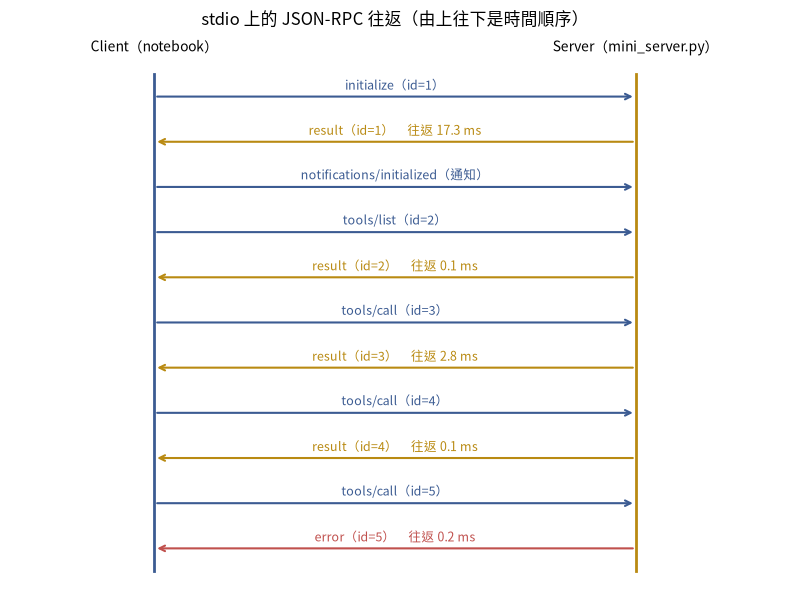

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for x, color in [(0, "#3b5b92"), (1, "#b98a12")]:
    ax.plot([x, x], [-0.5, len(log) - 0.5], color=color, lw=2)
ax.text(0, -1, "Client（notebook）", ha="center")
ax.text(1, -1, "Server（mini_server.py）", ha="center")
for y, (direction, label, ms) in enumerate(log):
    x0, x1 = (0, 1) if direction == "→" else (1, 0)
    color = "#3b5b92" if direction == "→" else ("#c0504d" if "error" in label else "#b98a12")
    ax.annotate("", xy=(x1, y), xytext=(x0, y), arrowprops=dict(arrowstyle="->", color=color, lw=1.5))
    text = label if ms is None else f"{label}　往返 {ms:.1f} ms"
    ax.text(0.5, y - 0.12, text, ha="center", va="bottom", fontsize=9, color=color)
ax.set_xlim(-0.3, 1.3)
ax.set_ylim(len(log) - 0.3, -1.4)
ax.axis("off")
ax.set_title("stdio 上的 JSON-RPC 往返（由上往下是時間順序）")
plt.tight_layout()
plt.show()

往右的箭頭是請求，往左的是回應。通知（`notifications/initialized`）只有往右、沒有回頭。
紅色那筆是呼叫不存在的工具，server 回 `error`。第一筆比較慢，是因為 server 行程剛啟動、還在載入 Python；之後每次往返都在 1 毫秒上下：stdio 就是兩條管線，沒有網路。

## Step 8：先看它壞掉——在 server 裡加一行除錯 print

很多人寫 server 的第一個習慣是 `print("收到請求")` 來除錯。我們把這行加進去看看。

In [10]:
src = Path("outputs/mini_server.py").read_text(encoding="utf-8")
bad = src.replace("    msg = json.loads(line)\n", "    msg = json.loads(line)\n    print('debug: 收到', msg.get('method'))\n")
Path("outputs/mini_server_bad.py").write_text(bad, encoding="utf-8")

bad_proc = start("outputs/mini_server_bad.py")
try:
    send(bad_proc, {"jsonrpc": "2.0", "id": 1, "method": "initialize", "params": {}})
except json.JSONDecodeError as exc:
    print("\n解析失敗：", exc)
finally:
    bad_proc.kill()

→ {"jsonrpc": "2.0", "id": 1, "method": "initialize", "params": {}}
← debug: 收到 initialize

解析失敗： Expecting value: line 1 column 1 (char 0)


client 讀到的第一行是 `debug: 收到 initialize`，不是 JSON，連線當場就壞了。
真實的 Host（Claude Desktop、Cursor）遇到這種情況，通常只會顯示「連線逾時」或「解析錯誤」，很難猜到原因。

**修法**：stdio server 裡不留任何 `print()`。要記錄就用 `logging`，它預設寫到 stderr，那是另一條管線，不會干擾協定。

## Step 9：真的 MCP server 也是說這些 JSON

`servers/ops_server.py` 是用官方 SDK 寫的 server（下一本會細看）。我們不用 SDK 的 client，直接用剛剛的 `send` 跟它講話。
真的協定要求 `initialize` 帶上版本與 client 資訊，其餘跟我們的迷你版一樣。

In [11]:
log.clear()
ops = start("servers/ops_server.py")
send(ops, {"jsonrpc": "2.0", "id": 1, "method": "initialize",
           "params": {"protocolVersion": "2025-06-18", "capabilities": {},
                      "clientInfo": {"name": "hand-made-client", "version": "0.1"}}})
send(ops, {"jsonrpc": "2.0", "method": "notifications/initialized"})

→ {"jsonrpc": "2.0", "id": 1, "method": "initialize", "params": {"protocolVersion": "2025-06-18", "capabilities": {}, "clientInfo": {"name": "hand-made-client", "version": "0.1"}}}
← {"jsonrpc":"2.0","id":1,"result":{"protocolVersion":"2025-06-18","capabilities":{"experimental":{},"prompts":{"listChanged":false},"resources":{"subscribe":false,"listChanged":false},"tools":{"listChanged":false}},"serverInfo":{"name":"ops","version":"1.30.0"},"instructions":"星港物流的唯讀維運查詢：服務狀態、日誌、值班手 …（後面截斷）
→ {"jsonrpc": "2.0", "method": "notifications/initialized"}


In [12]:
reply = send(ops, {"jsonrpc": "2.0", "id": 2, "method": "tools/list"})
print("\n工具：", [t["name"] for t in reply["result"]["tools"]])

→ {"jsonrpc": "2.0", "id": 2, "method": "tools/list"}
← {"jsonrpc":"2.0","id":2,"result":{"tools":[{"name":"get_service_status","description":"查詢一個服務目前的狀態：state、p95 延遲（毫秒）、錯誤率、版本。","inputSchema":{"properties":{"service":{"enum":["payment","order","inventory"],"title":"Service","type":"string"}},"required":["service"],"title":"get_service_statusArguments" …（後面截斷）

工具： ['get_service_status', 'search_logs', 'list_services']


In [13]:
reply = send(ops, {"jsonrpc": "2.0", "id": 3, "method": "tools/call",
                   "params": {"name": "get_service_status", "arguments": {"service": "payment"}}})
ops.stdin.close()
ops.wait(timeout=10)
print("\nserver 寫到 stderr 的日誌：")
print(ops.stderr.read().strip())

→ {"jsonrpc": "2.0", "id": 3, "method": "tools/call", "params": {"name": "get_service_status", "arguments": {"service": "payment"}}}
← {"jsonrpc":"2.0","id":3,"result":{"content":[{"type":"text","text":"{\"service\": \"payment\", \"state\": \"degraded\", \"p95_ms\": 2310, \"error_rate\": 0.084, \"version\": \"v3.2.1\"}"}],"structuredContent":{"result":"{\"service\": \"payment\", \"state\": \"degraded\", \"p95_ms\": 2310, \"error_ra …（後面截斷）

server 寫到 stderr 的日誌：
[ops-server] get_service_status(payment)


回應的形狀跟迷你 server 一樣：`result.tools`、`result.content[0].text`。官方 SDK 幫你做的事主要是：
從型別註記產生 `inputSchema`、驗證參數、處理版本協商與錯誤。底層就是你剛剛手寫的那些 JSON。

另外注意 server 自己的日誌（`[ops-server] ...`）是從 stderr 讀到的，沒有混進協定通道。

## 試試看

1. 在 `mini_server.py` 加一個工具 `reverse(text)`，重跑 Step 6，用 `tools/list` 確認它出現了。
2. 一次連送兩個 `tools/call` 請求（先 write 兩行，再 readline 兩次），觀察回應的 `id`。如果 server 是多執行緒、回應順序可能顛倒，client 要怎麼對？
3. 把 Step 8 的 `print(...)` 改成 `print(..., file=sys.stderr)`，再跑一次，連線還會壞嗎？

## 小結

- 沒有標準時，N 個 app × M 個工具要寫 N×M 份轉接；MCP 把它變成 N+M。
- MCP 底層是 JSON-RPC：stdio 傳輸就是子行程的 stdin/stdout，一行一則訊息，所以 server 裡不能亂 `print()`。
- 下一本改用官方 SDK 的 client 連 `ops_server.py`，並把它的工具接上本地模型，做出一個會查日誌的 agent。